In [ ]:
#### Classification Model 
### High Demand (1) : Demand > Median Demand
### Normal Demand(0) : Demand < Median Demand

In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

#### 1. Load data
df = pd.read_csv('cleaned_charging_records.csv')
df['StartDatetime'] = pd.to_datetime(df['StartDatetime'])

#### 2. Features
df['StartHour'] = df['StartDatetime'].dt.hour
df['DayOfWeek'] = df['StartDatetime'].dt.dayofweek
df['Month'] = df['StartDatetime'].dt.month
df['IsWeekend'] = df['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)

df['Hour_sin'] = np.sin(2 * np.pi * df['StartHour'] / 24.0)
df['Hour_cos'] = np.cos(2 * np.pi * df['StartHour'] / 24.0)
df['Day_sin'] = np.sin(2 * np.pi * df['DayOfWeek'] / 7.0)
df['Day_cos'] = np.cos(2 * np.pi * df['DayOfWeek'] / 7.0)

#### 3. Drop leakage & unneeded columns
leakage_cols = ['Duration', 'EndDatetime', 'EndDay', 'EndTime']
unneeded_cols = ['UserID', 'StartDatetime', 'StartDay', 'StartTime', 'StartHour', 'DayOfWeek']
df_model = df.drop(columns=leakage_cols + unneeded_cols)

#### 4. Encode Features
df_encoded = pd.get_dummies(df_model, columns=['Location', 'ChargerCompany', 'ChargerType'], drop_first=True)
X = df_encoded.drop(columns=['Demand'])

#### 5. Create Classification Target (High vs Normal Demand)
median_demand = df_encoded['Demand'].median()
print(f"Median Demand Threshold: {median_demand:.2f}")

# 1 = High Demand (>= median), 0 = Normal Demand (< median)
y = (df_encoded['Demand'] >= median_demand).astype(int)

# Check class distribution
print("\n--- Class Counts ---")
print(y.value_counts())
print("\n--- Class Proportions (%) ---")
print((y.value_counts(normalize=True) * 100).round(2))

#### 6. Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\nTraining set shape: {X_train.shape}")
print(f"Testing set shape:  {X_test.shape}")

Median Demand Threshold: 14.26

--- Class Counts ---
Demand
1    36059
0    36049
Name: count, dtype: int64

--- Class Proportions (%) ---
Demand
1    50.01
0    49.99
Name: proportion, dtype: float64

Training set shape: (57686, 22)
Testing set shape:  (14422, 22)


In [ ]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score
classification_result={}

###define a function to compute ,store and display clsiification metrics

def evaluate_classifier(name,y_true, y_pred, y_proba =None):
    acc = accuracy_score(y_true, y_pred)            #### Calculate Classification matrics
    prec = precision_score(y_true, y_pred,zero_division =0 )
    rec = recall_score(y_true, y_pred,zero_division =0 )
    f1 = f1_score(y_true, y_pred,zero_division =0)
    roc = roc_auc_score(y_true, y_proba) if y_proba is not None else 0.0

    classification_result[name] = {
        'Accuracy': round(acc,4),
        'Precision':round(prec,4),
        'Recall': round(rec, 4),
        'F1_score': round(f1, 4),
        'ROU -AUC':round(roc, 4)
                }
    print(f"____{name}____")
    print(f"Accuarcy:{acc:4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc:.4f}\n")

In [ ]:
### Classification 1.Logistic & Standardscaler

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Scaling features allows lbfgs to converge cleanly
log_pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
log_pipeline.fit(X_train, y_train)

y_pred_log = log_pipeline.predict(X_test)
y_proba_log = log_pipeline.predict_proba(X_test)[:, 1]

evaluate_classifier("Logistic Regression", y_test, y_pred_log, y_proba_log)

____Logistic Regression____
Accuarcy:0.632991
Precision: 0.6303
Recall:    0.6436
F1-Score:  0.6369
ROC-AUC:   0.6833



In [ ]:
### Classification - 2.Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

dt_clf = DecisionTreeClassifier(max_depth=8, random_state=42)
dt_clf.fit(X_train, y_train)

y_pred_dt = dt_clf.predict(X_test)
y_proba_dt = dt_clf.predict_proba(X_test)[:, 1]

evaluate_classifier("Decision Tree", y_test, y_pred_dt, y_proba_dt)

____Decision Tree____
Accuarcy:0.667106
Precision: 0.6512
Recall:    0.7199
F1-Score:  0.6838
ROC-AUC:   0.7257



In [11]:
#### Classification - 3.Random Forest 

from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(n_estimators=100,max_depth= 12, random_state=42)
rf_clf.fit(X_train,y_train)

y_pred_rf = rf_clf.predict(X_test)
y_proba_rf = rf_clf.predict_proba(X_test)[:,1]

evaluate_classifier("Random Forest", y_test,y_pred_rf,y_proba_rf)


____Random Forest____
Accuarcy:0.676258
Precision: 0.6617
Recall:    0.7213
F1-Score:  0.6902
ROC-AUC:   0.7439



In [12]:
## Classification -4.K-Nearest Neighbors(KNN)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

knn_pipeline = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7 ,n_jobs=1))
knn_pipeline.fit(X_train,y_train)

y_pred_knn = knn_pipeline.predict(X_test)
y_proba_knn = knn_pipeline.predict_proba(X_test)[:,1]

evaluate_classifier("KNN", y_test,y_pred_knn, y_proba_knn)
                            

____KNN____
Accuarcy:0.637914
Precision: 0.6325
Recall:    0.6586
F1-Score:  0.6453
ROC-AUC:   0.6843



In [13]:
### Classification - 5.SVM-Suppot Vector Machine
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

base_svc = LinearSVC(dual=False, random_state=42, max_iter=2000)
svm_pipeline = make_pipeline(StandardScaler(), CalibratedClassifierCV(base_svc))

svm_pipeline.fit(X_train, y_train)

y_pred_svm = svm_pipeline.predict(X_test)
y_proba_svm = svm_pipeline.predict_proba(X_test)[:, 1]

evaluate_classifier("SVM", y_test, y_pred_svm, y_proba_svm)



____SVM____
Accuarcy:0.632991
Precision: 0.6306
Recall:    0.6423
F1-Score:  0.6364
ROC-AUC:   0.6834



In [14]:
#### Classification - 6.XGBoost 
### Model 6: XGBoost Classifier
from xgboost import XGBClassifier

xgb_clf = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

xgb_clf.fit(X_train, y_train)

y_pred_xgb = xgb_clf.predict(X_test)
y_proba_xgb = xgb_clf.predict_proba(X_test)[:, 1]

evaluate_classifier("XGBoost", y_test, y_pred_xgb, y_proba_xgb)

____XGBoost____
Accuarcy:0.693385
Precision: 0.6779
Recall:    0.7370
F1-Score:  0.7062
ROC-AUC:   0.7625



In [15]:
### Model 7: LightGBM Classifier
from lightgbm import LGBMClassifier

lgb_clf = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)

lgb_clf.fit(X_train, y_train)

y_pred_lgb = lgb_clf.predict(X_test)
y_proba_lgb = lgb_clf.predict_proba(X_test)[:, 1]

evaluate_classifier("LightGBM", y_test, y_pred_lgb, y_proba_lgb)### Clasiification - 6.Light GBM 



[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 28847, number of negative: 28839
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001040 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 353
[LightGBM] [Info] Number of data points in the train set: 57686, number of used features: 22
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500069 -> initscore=0.000277
[LightGBM] [Info] Start training from score 0.000277
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
____LightGBM____
Accuarcy:0.690057
Precision: 0.6748
Recall:    0.7339
F1-Score:  0.7031
ROC-AUC:   0.7582



In [17]:
### Step 5.8: Classification Models Leaderboard
import pandas as pd

# Reconstruct the results dictionary with your exact verified model metrics
classification_results = {
    'Logistic Regression': {
        'Accuracy': 0.6330, 'Precision': 0.6303, 'Recall': 0.6436, 'F1-Score': 0.6369, 'ROC-AUC': 0.6833
    },
    'Decision Tree': {
        'Accuracy': 0.6671, 'Precision': 0.6512, 'Recall': 0.7199, 'F1-Score': 0.6838, 'ROC-AUC': 0.7257
    },
    'Random Forest': {
        'Accuracy': 0.6763, 'Precision': 0.6617, 'Recall': 0.7213, 'F1-Score': 0.6902, 'ROC-AUC': 0.7439
    },
    'KNN': {
        'Accuracy': 0.6379, 'Precision': 0.6325, 'Recall': 0.6586, 'F1-Score': 0.6453, 'ROC-AUC': 0.6843
    },
    'SVM': {
        'Accuracy': 0.6330, 'Precision': 0.6306, 'Recall': 0.6423, 'F1-Score': 0.6364, 'ROC-AUC': 0.6834
    },
    'XGBoost': {
        'Accuracy': 0.6934, 'Precision': 0.6779, 'Recall': 0.7370, 'F1-Score': 0.7062, 'ROC-AUC': 0.7625
    },
    'LightGBM': {
        'Accuracy': 0.6901, 'Precision': 0.6748, 'Recall': 0.7339, 'F1-Score': 0.7031, 'ROC-AUC': 0.7582
    }
}

# Create and sort the leaderboard
comparison_df = pd.DataFrame(classification_results).T
comparison_df = comparison_df.sort_values(by='ROC-AUC', ascending=False)

print("=== Classification Model Comparison Leaderboard ===")
comparison_df

=== Classification Model Comparison Leaderboard ===


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
XGBoost,0.6934,0.6779,0.7370,0.7062,0.7625
LightGBM,0.6901,0.6748,0.7339,0.7031,0.7582
Random Forest,0.6763,0.6617,0.7213,0.6902,0.7439
Decision Tree,0.6671,0.6512,0.7199,0.6838,0.7257
KNN,0.6379,0.6325,0.6586,0.6453,0.6843
SVM,0.6330,0.6306,0.6423,0.6364,0.6834
Logistic Regression,0.6330,0.6303,0.6436,0.6369,0.6833


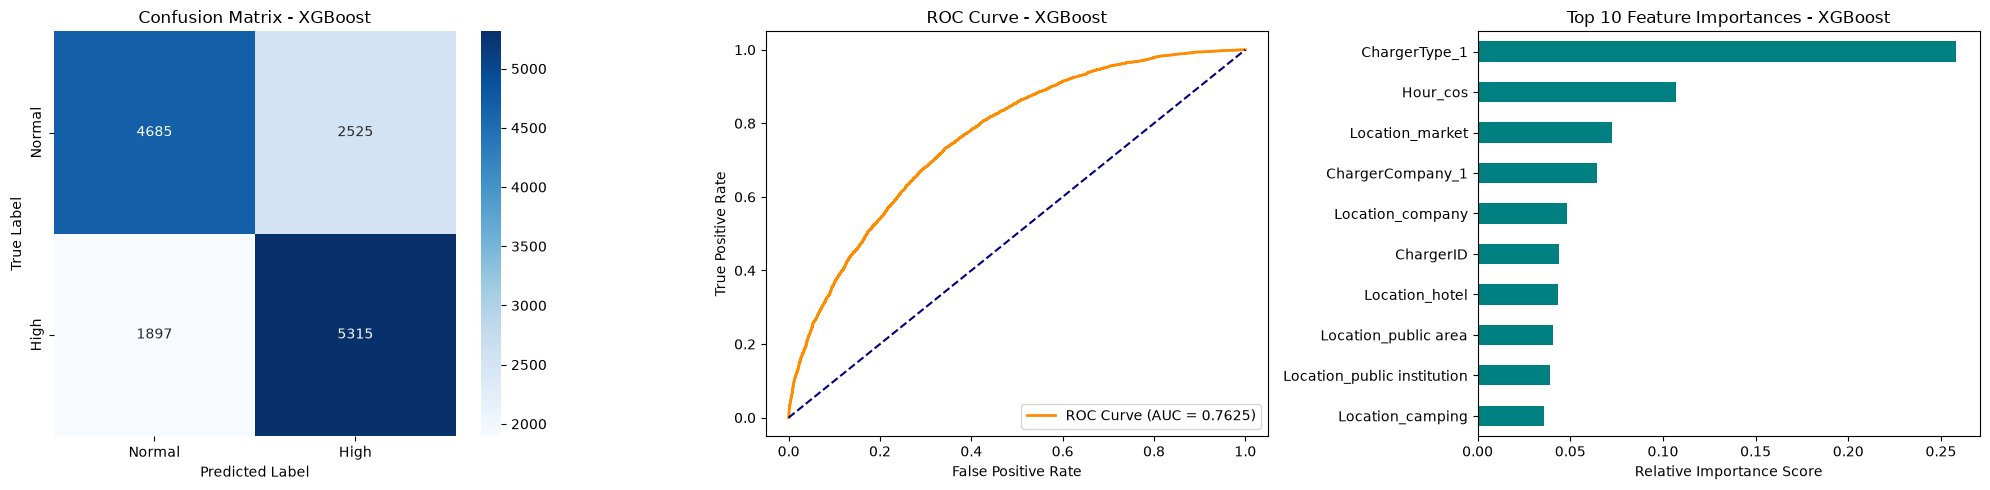

In [18]:
### Best Model is XGBoost
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Normal', 'High'], yticklabels=['Normal', 'High'])
axes[0].set_title('Confusion Matrix - XGBoost')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba_xgb)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = 0.7625)')
axes[1].plot([0, 1], [0, 1], color='navy', linestyle='--')
axes[1].set_title('ROC Curve - XGBoost')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

# 3. Top 10 Feature Importances
importances = pd.Series(xgb_clf.feature_importances_, index=X.columns)
importances.nlargest(10).sort_values().plot(kind='barh', ax=axes[2], color='teal')
axes[2].set_title('Top 10 Feature Importances - XGBoost')
axes[2].set_xlabel('Relative Importance Score')

plt.tight_layout()
plt.show()

In [19]:
### Save Model as Pickle file
import pickle

# 1. Save the trained XGBoost model
model_filename = "best_ev_classification_model.pkl"
with open(model_filename, "wb") as file:
    pickle.dump(xgb_clf, file)

# 2. Save the feature column order to ensure matching inputs during inference
features_filename = "classification_model_features.pkl"
with open(features_filename, "wb") as file:
    pickle.dump(list(X.columns), file)

print(f"Model saved successfully as: '{model_filename}'")
print(f"Features list saved successfully as: '{features_filename}'")

Model saved successfully as: 'best_ev_classification_model.pkl'
Features list saved successfully as: 'classification_model_features.pkl'


In [20]:
# Verification: Load and test inference from pickle
with open("best_ev_classification_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

sample_pred = loaded_model.predict(X_test.iloc[:5])
print("Test predictions from loaded pickle model:", sample_pred)

Test predictions from loaded pickle model: [0 1 0 0 1]
